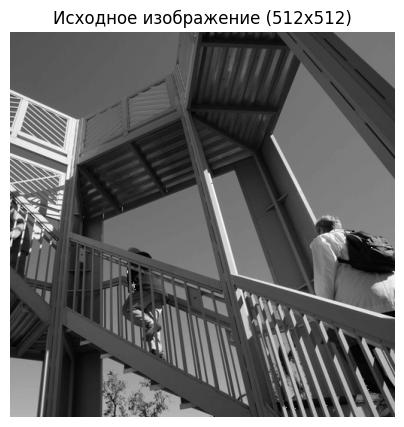

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import datasets

img = datasets.ascent().astype(np.float64)
img = cv2.resize(img, (512, 512))

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title(f'Исходное изображение ({img.shape[0]}x{img.shape[1]})')
plt.axis('off')
plt.show()

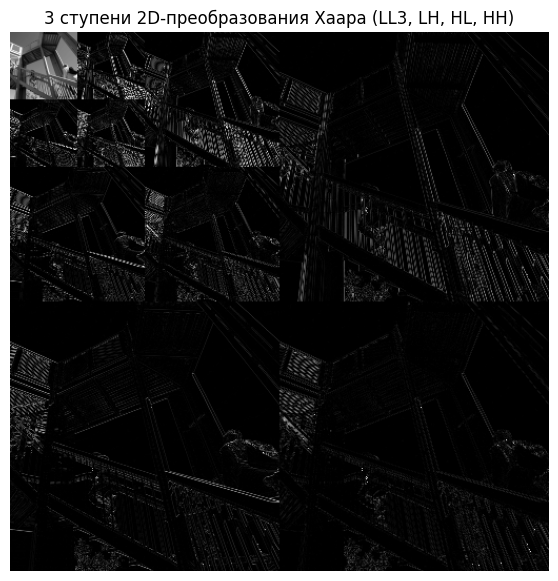

In [2]:
def haar_1d_forward(vec):
    n = vec.shape[-1]
    even = vec[..., 0::2]
    odd = vec[..., 1::2]
    low = (even + odd) / np.sqrt(2.0)
    high = (even - odd) / np.sqrt(2.0)
    return np.concatenate([low, high], axis=-1)

def haar_1d_inverse(vec):
    n = vec.shape[-1]
    half = n // 2
    low = vec[..., :half]
    high = vec[..., half:]
    even = (low + high) / np.sqrt(2.0)
    odd = (low - high) / np.sqrt(2.0)
    res = np.empty_like(vec)
    res[..., 0::2] = even
    res[..., 1::2] = odd
    return res

def haar_2d_forward(image, levels=3):
    coeffs = image.copy().astype(np.float64)
    h, w = coeffs.shape
    for _ in range(levels):
        sub = coeffs[:h, :w]
        sub = haar_1d_forward(sub)
        sub = haar_1d_forward(sub.T).T
        coeffs[:h, :w] = sub
        h //= 2
        w //= 2
    return coeffs

def haar_2d_inverse(coeffs, levels=3):
    rec = coeffs.copy().astype(np.float64)
    h, w = rec.shape
    h //= (2 ** (levels - 1))
    w //= (2 ** (levels - 1))
    for _ in range(levels):
        sub = rec[:h, :w]
        sub = haar_1d_inverse(sub.T).T
        sub = haar_1d_inverse(sub)
        rec[:h, :w] = sub
        h *= 2
        w *= 2
    return rec

levels = 3
haar_coeffs = haar_2d_forward(img, levels=levels)

vis = np.zeros_like(haar_coeffs)
h, w = img.shape
for l in range(levels):
    hh, ww = h // (2 ** (l + 1)), w // (2 ** (l + 1))
    for r_slice, c_slice in [(slice(0, hh), slice(ww, 2*ww)),
                             (slice(hh, 2*hh), slice(0, ww)),
                             (slice(hh, 2*hh), slice(ww, 2*ww))]:
        band = np.abs(haar_coeffs[r_slice, c_slice])
        vis[r_slice, c_slice] = (band / (band.max() + 1e-8)) * 255.0

ll_h, ll_w = h // (2 ** levels), w // (2 ** levels)
ll_band = haar_coeffs[:ll_h, :ll_w]
vis[:ll_h, :ll_w] = ((ll_band - ll_band.min()) / (ll_band.max() - ll_band.min() + 1e-8)) * 255.0

plt.figure(figsize=(7, 7))
plt.imshow(vis, cmap='gray')
plt.title('3 ступени 2D-преобразования Хаара (LL3, LH, HL, HH)')
plt.axis('off')
plt.show()

Порог =  0.0 | Нулей: 23.44% | Сжатие:  1.31x | RMSE:  0.000 | PSNR: 309.47 dB
Порог = 10.0 | Нулей: 80.35% | Сжатие:  5.09x | RMSE:  2.578 | PSNR:  39.90 dB
Порог = 30.0 | Нулей: 91.05% | Сжатие: 11.17x | RMSE:  6.522 | PSNR:  31.84 dB
Порог = 60.0 | Нулей: 95.28% | Сжатие: 21.20x | RMSE: 11.040 | PSNR:  27.27 dB


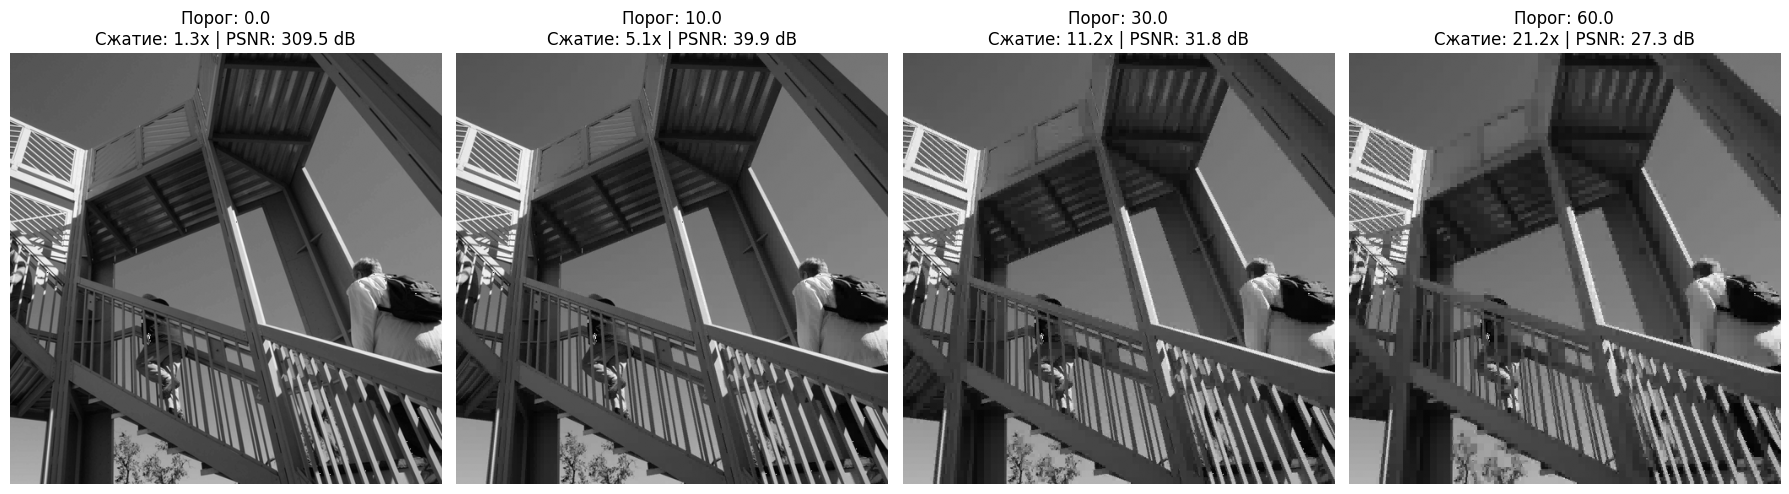

In [3]:
def compress_haar(coeffs, threshold, levels=3):
    compressed = coeffs.copy()
    h, w = compressed.shape
    ll_h, ll_w = h // (2 ** levels), w // (2 ** levels)
    ll_backup = compressed[:ll_h, :ll_w].copy()
    compressed[np.abs(compressed) < threshold] = 0.0
    compressed[:ll_h, :ll_w] = ll_backup
    return compressed

def compute_metrics(orig, rec, compressed_coeffs):
    rmse = np.sqrt(np.mean((orig - rec) ** 2))
    psnr = 20.0 * np.log10(255.0 / rmse) if rmse > 0 else float('inf')
    total_coeffs = compressed_coeffs.size
    nonzero_coeffs = np.count_nonzero(compressed_coeffs)
    compression_ratio = total_coeffs / nonzero_coeffs
    zeros_percent = (1.0 - nonzero_coeffs / total_coeffs) * 100.0
    return rmse, psnr, compression_ratio, zeros_percent

thresholds = [0.0, 10.0, 30.0, 60.0]

fig, axes = plt.subplots(1, len(thresholds), figsize=(18, 5))

for ax, thr in zip(axes, thresholds):
    comp_coeffs = compress_haar(haar_coeffs, threshold=thr, levels=levels)
    reconstructed = np.clip(haar_2d_inverse(comp_coeffs, levels=levels), 0, 255)
    rmse, psnr, cr, zeros_pct = compute_metrics(img, reconstructed, comp_coeffs)

    print(f"Порог = {thr:4.1f} | Нулей: {zeros_pct:5.2f}% | Сжатие: {cr:5.2f}x | RMSE: {rmse:6.3f} | PSNR: {psnr:6.2f} dB")

    ax.imshow(reconstructed, cmap='gray')
    ax.set_title(f'Порог: {thr}\nСжатие: {cr:.1f}x | PSNR: {psnr:.1f} dB')
    ax.axis('off')

plt.tight_layout()
plt.show()